<img src="https://raw.githubusercontent.com/riazcseiu/fmlds2026-multimodal-workshop/main/assets/banner.png" width="100%">

# Notebook 4 · Fusion: Said vs Did
**Combining language and vision**  ·  ⏱ about 15 minutes

### What you will learn
- Fuse stall-level **perceptual (P)** and **behavioural (B)** scores — late fusion
- Compute the **perceptual–behavioural gap** Δ = B − P and classify stalls
- Build your own P from the interviews and compare it with the paper
- Explain the gaps with ad configuration, product–event fit and audience alignment
- Analyse the **live audience data** from our group activity

> **The story so far.** At the *Imagine Coffee Event* — a two-hour Sunday-morning pop-up market in Matsue, Japan — we asked visitors what they noticed (**interviews → language**) and we filmed what they actually did (**video → vision**).
> This workshop combines both modalities to answer one question: *do people do what they say?*

<small>Data: a reduced, anonymised teaching subset derived from Mian & Nguyen-Tran (World 2026) and Nguyen-Tran, Majiid & Mian (World 2025). Names removed, participants sub-sampled, ~10% of utterances dropped. Do not use for research claims.</small>


In [1]:
# ▶ Run this cell first — it fetches the workshop data (about 20 s in Colab)
import os, sys, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/riazcseiu/fmlds2026-multimodal-workshop'
if IN_COLAB:
    if not os.path.exists('fmlds2026-multimodal-workshop'):
        os.system(f'git clone -q --depth 1 {REPO_URL}')
    BASE = 'fmlds2026-multimodal-workshop'
else:
    BASE = '..'          # running locally from the notebooks/ folder
DATA = os.path.join(BASE, 'data')
RESULTS = os.path.join(BASE, 'data', 'results'); os.makedirs(RESULTS, exist_ok=True)

import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 11})
COL = {'onsite': '#2A9D8F', 'video': '#4361EE', 'virtual': '#9B5DE5', 'P': '#4361EE', 'B': '#D9731A'}
print('Data folder:', os.path.abspath(DATA))

## 1 · Why fuse at the end?
Our two pipelines stay **independent** until the last step (*late fusion*). If interview answers influenced how we scored the video — or the other way round — we could no longer see where they disagree. And the disagreement is exactly what we want to find.

```
Interviews ─► keywords ─► weighting ─► P (0–5) ┐
                                               ├─► Δ = B − P ─► explain
Video ─► YOLO ─► DeepSORT ─► stops ─► B (0–5) ┘
```

In [2]:
st = pd.read_csv(f'{DATA}/stall_scores_paper.csv')
st[['stall_id', 'category', 'P_perceptual_0to5', 'B_behavioral_0to5']]

,stall_id,category,P_perceptual_0to5,B_behavioral_0to5
0,1,Flower and Plant,3.958,2.755
1,2,Fresh Produce,2.664,1.589
2,3,Fresh Produce,2.352,1.943
3,4,Beverages,3.579,4.079
4,5,Sweets and Baked Goods,1.491,2.714
5,6,Prepared Meal,1.438,4.578
6,7,Japanese Food,0.625,4.330
7,8,Hot Food and Seafood,3.710,2.853


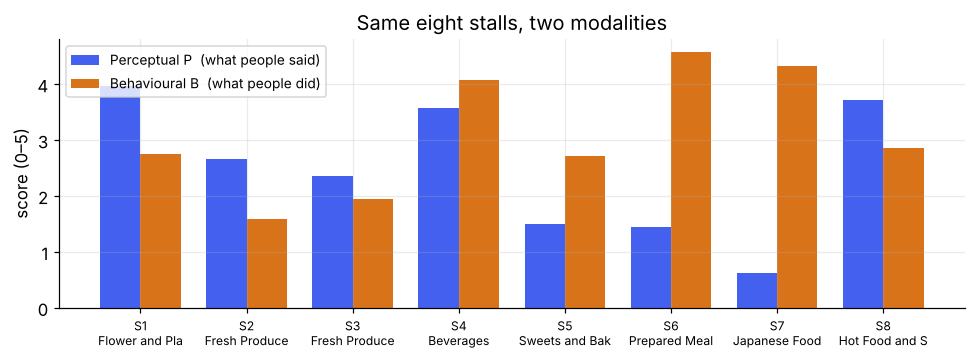

In [3]:
x = np.arange(8); w = .38
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(x - w/2, st.P_perceptual_0to5, w, color=COL['P'], label='Perceptual P  (what people said)')
ax.bar(x + w/2, st.B_behavioral_0to5, w, color=COL['B'], label='Behavioural B  (what people did)')
ax.set_xticks(x); ax.set_xticklabels([f'S{i}\n{c[:14]}' for i, c in zip(st.stall_id, st.category)], fontsize=8)
ax.set_ylabel('score (0–5)'); ax.legend(fontsize=9); ax.set_title('Same eight stalls, two modalities')
plt.tight_layout(); plt.show()

## 2 · The gap  Δᵢ = Bᵢ − Pᵢ
- **Δ > 0** → visitors *did* more than interviews predicted (a **quiet winner**)
- **Δ < 0** → interviews over-estimated the stall (a **loud loser**)
- **Δ ≈ 0** → both modalities agree

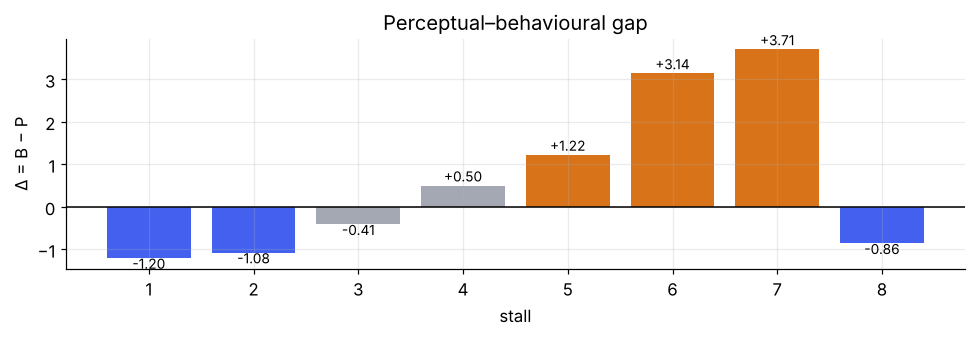

,stall_id,category,gap,group
0,1,Flower and Plant,-1.20,below expectation
1,2,Fresh Produce,-1.08,below expectation
2,3,Fresh Produce,-0.41,roughly aligned
3,4,Beverages,0.50,roughly aligned
4,5,Sweets and Baked Goods,1.22,above expectation
5,6,Prepared Meal,3.14,above expectation
6,7,Japanese Food,3.70,above expectation
7,8,Hot Food and Seafood,-0.86,below expectation


In [4]:
THRESH = 0.6
st['gap'] = st.B_behavioral_0to5 - st.P_perceptual_0to5
st['group'] = np.select([st.gap > THRESH, st.gap < -THRESH], ['above expectation', 'below expectation'], 'roughly aligned')
gcol = {'above expectation': COL['B'], 'below expectation': COL['P'], 'roughly aligned': '#A3A8B3'}
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(st.stall_id, st.gap, color=st.group.map(gcol))
for i, g in zip(st.stall_id, st.gap): ax.text(i, g + (.1 if g > 0 else -.25), f'{g:+.2f}', ha='center', fontsize=9)
ax.axhline(0, color='k', lw=1); ax.set_xticks(st.stall_id); ax.set_xlabel('stall'); ax.set_ylabel('Δ = B − P')
ax.set_title('Perceptual–behavioural gap'); plt.tight_layout(); plt.show()
st[['stall_id', 'category', 'gap', 'group']].round(2)

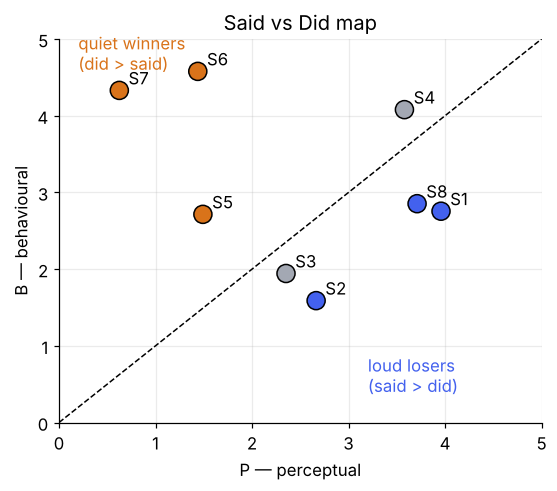

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(st.P_perceptual_0to5, st.B_behavioral_0to5, s=140, c=st.group.map(gcol), edgecolor='k', zorder=3)
for r in st.itertuples(): ax.annotate(f'S{r.stall_id}', (r.P_perceptual_0to5, r.B_behavioral_0to5), xytext=(6, 4), textcoords='offset points')
ax.plot([0, 5], [0, 5], 'k--', lw=1); ax.set_xlim(0, 5); ax.set_ylim(0, 5)
ax.text(.2, 4.6, 'quiet winners\n(did > said)', color=COL['B']); ax.text(3.2, .4, 'loud losers\n(said > did)', color=COL['P'])
ax.set_xlabel('P — perceptual'); ax.set_ylabel('B — behavioural'); ax.set_title('Said vs Did map')
plt.tight_layout(); plt.show()

## 3 · Build your own P from the interviews
The paper's P came from 8 observers answering 17 structured questions. Here we compute a quick P from the three-modality interviews in this repository: how often (and how positively) is each stall's product mentioned?

In [6]:
import re
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
except ImportError:
    os.system('pip -q install vaderSentiment'); from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
df = pd.read_csv(f'{DATA}/interviews/imagine_coffee_all.csv'); part = df[df.role == 'participant'].copy()
part['s'] = part.text.astype(str).map(lambda t: (vader.polarity_scores(t)['compound'] + 1) / 2)   # 0..1
sd = pd.read_csv(f'{DATA}/keywords/stall_dictionary.csv')
rows = []
for r in part.itertuples():
    for st_ in sd.itertuples():
        if re.search(r'\b(' + st_.variants + r')\b', str(r.text), re.I):
            rows.append(dict(stall_id=st_.stall_id, session=r.modality + r.session, s=r.s))
sm = pd.DataFrame(rows)
# one vote per participant per stall, weighted by sentiment → avoids verbosity inflation
myP = sm.groupby(['stall_id', 'session']).s.mean().groupby('stall_id').sum().reindex(range(1, 9), fill_value=0)
st['P_ours'] = (5 * myP / myP.max()).values
print('correlation with paper P:', round(st[['P_ours', 'P_perceptual_0to5']].corr().iloc[0, 1], 2))
st[['stall_id', 'category', 'P_perceptual_0to5', 'P_ours', 'B_behavioral_0to5']].round(2)

correlation with paper P: 0.44


,stall_id,category,P_perceptual_0to5,P_ours,B_behavioral_0to5
0,1,Flower and Plant,3.96,4.25,2.76
1,2,Fresh Produce,2.66,4.71,1.59
2,3,Fresh Produce,2.35,2.16,1.94
3,4,Beverages,3.58,3.85,4.08
4,5,Sweets and Baked Goods,1.49,3.77,2.71
5,6,Prepared Meal,1.44,5.00,4.58
6,7,Japanese Food,0.62,1.24,4.33
7,8,Hot Food and Seafood,3.71,4.00,2.85


**Discuss:** where does your P agree with the paper, and where not? Different people, different questions, different modality — perception data is fragile with small samples. That is precisely why we check it against behaviour.

## 4 · Why the gaps? Three explanatory factors

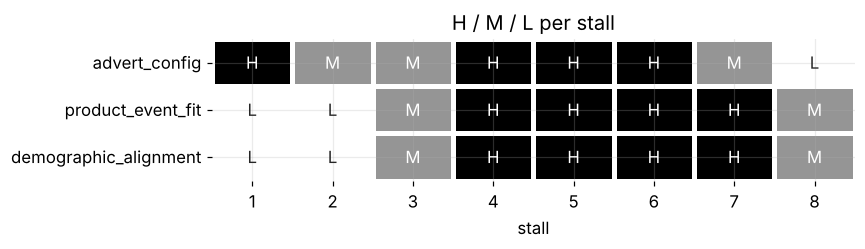

correlation of each factor with the gap Δ: {'advert_config': 0.26, 'product_event_fit': 0.81, 'demographic_alignment': 0.81}


In [7]:
import seaborn as sns
fac = st.set_index('stall_id')[['advert_config', 'product_event_fit', 'demographic_alignment']].T
num = fac.replace({'H': 2, 'M': 1, 'L': 0}).astype(float)
fig, ax = plt.subplots(figsize=(8, 2.4))
sns.heatmap(num, annot=fac, fmt='', cmap='Greys', cbar=False, linewidths=2, ax=ax)
ax.set_xlabel('stall'); ax.set_ylabel(''); ax.set_title('H / M / L per stall'); plt.tight_layout(); plt.show()
corr = {f: round(float(np.corrcoef(num.loc[f], st.gap)[0, 1]), 2) for f in num.index}
print('correlation of each factor with the gap Δ:', corr)

**Fit beats looks.** Product–event fit and audience alignment track the gap much better than how good the advertising looked. Flowers had good signage but little fit with a coffee morning; prepared meals and Japanese food had modest signage but fitted exactly the people who came at 7 a.m.

## 5 · 🙋 Live group activity — your data
During the workshop you scanned a QR code and answered: *which stall would you visit first, and why (one sentence)?*
Paste the CSV link shown on the screen below (or use the sample file) and re-run.

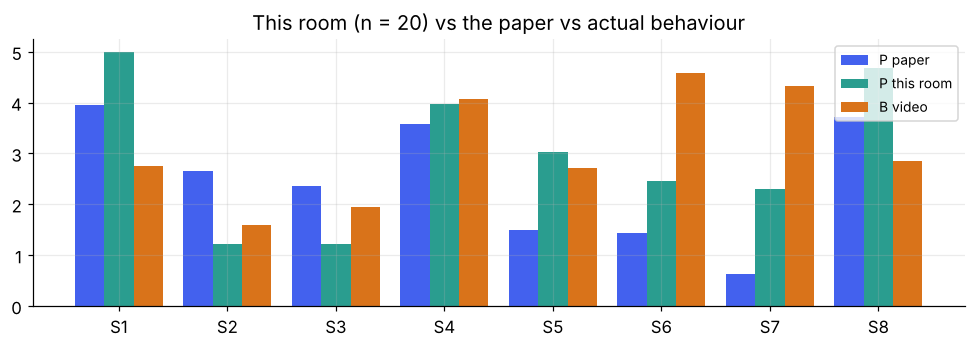

In [8]:
AUDIENCE_CSV = f'{DATA}/audience/audience_sample.csv'   # ← replace with the link shown on screen
aud = pd.read_csv(AUDIENCE_CSV)
aud['s'] = aud.reason.astype(str).map(lambda t: (vader.polarity_scores(t)['compound'] + 1) / 2)
audP = aud.groupby('stall_id').s.sum().reindex(range(1, 9), fill_value=0)
st['P_audience'] = (5 * audP / max(audP.max(), 1e-9)).values
x = np.arange(8); w = .27
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.bar(x - w, st.P_perceptual_0to5, w, color=COL['P'], label='P paper')
ax.bar(x, st.P_audience, w, color='#2A9D8F', label='P this room')
ax.bar(x + w, st.B_behavioral_0to5, w, color=COL['B'], label='B video')
ax.set_xticks(x); ax.set_xticklabels([f'S{i}' for i in st.stall_id]); ax.legend(fontsize=9)
ax.set_title(f'This room (n = {len(aud)}) vs the paper vs actual behaviour'); plt.tight_layout(); plt.show()

### Group task (10 min)
In your group:
1. Pick **one** stall with a large gap.
2. Agree on **why** — use the three factors or your own idea.
3. Propose **one design change** for the organiser (layout, signage, product, timing).
4. Submit it on the live page and vote for the best proposal.

## 🎯 Take-aways
- Multimodal ≠ "more data". Each modality answers a different question: **why** (language) and **what / where** (vision).
- Keep pipelines independent and fuse late, so disagreement stays visible.
- The *gap* between modalities is the insight.

Thank you! Questions → **riaz@cis.shimane-u.ac.jp**